In [1]:

# Lane Radar - Model Evaluation
# Cell 1: Install required libraries

!pip install -q ultralytics torchvision pandas numpy matplotlib pillow tqdm


In [2]:

# Cell 2: Check environment

import torch
import torchvision
import ultralytics
import pandas as pd
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Ultralytics version:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. We are currently using CPU.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Ultralytics version: 8.4.199
GPU available: Tesla T4


In [3]:

# Cell 3: Load pretrained models

from ultralytics import YOLO
import torchvision
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

# Model 1: YOLOv8 Nano
yolov8_model = YOLO("yolov8n.pt")

# Model 2: YOLO11 Nano
yolo11_model = YOLO("yolo11n.pt")

# Model 3: Faster R-CNN ResNet50 FPN
faster_rcnn_model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
    weights=torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
)

faster_rcnn_model = faster_rcnn_model.to(device)
faster_rcnn_model.eval()

print("All three models loaded successfully!")
print("Device:", device)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 178MB/s]


All three models loaded successfully!
Device: cuda


In [4]:

# Cell 4: Test all three models on one sample image

import requests
from PIL import Image
from io import BytesIO
import torchvision.transforms as T

# Download a sample image
image_url = "https://ultralytics.com/images/bus.jpg"

response = requests.get(image_url)
response.raise_for_status()

sample_image = Image.open(BytesIO(response.content)).convert("RGB")

print("Sample image loaded:", sample_image.size)

# Test YOLOv8n
results_v8 = yolov8_model.predict(
    sample_image,
    classes=[0],
    verbose=False
)

count_v8 = len(results_v8[0].boxes)

# Test YOLO11n
results_11 = yolo11_model.predict(
    sample_image,
    classes=[0],
    verbose=False
)

count_11 = len(results_11[0].boxes)

# Test Faster R-CNN
transform = T.ToTensor()
image_tensor = transform(sample_image).to(device)

with torch.no_grad():
    faster_results = faster_rcnn_model([image_tensor])

# COCO class 1 = person
faster_boxes = faster_results[0]["boxes"]
faster_labels = faster_results[0]["labels"]
faster_scores = faster_results[0]["scores"]

count_faster = (
    (faster_labels == 1) &
    (faster_scores >= 0.5)
).sum().item()

print("\nSample inference results:")
print("YOLOv8n people detected:", count_v8)
print("YOLO11n people detected:", count_11)
print("Faster R-CNN people detected:", count_faster)


Sample image loaded: (810, 1080)

Sample inference results:
YOLOv8n people detected: 4
YOLO11n people detected: 4
Faster R-CNN people detected: 4


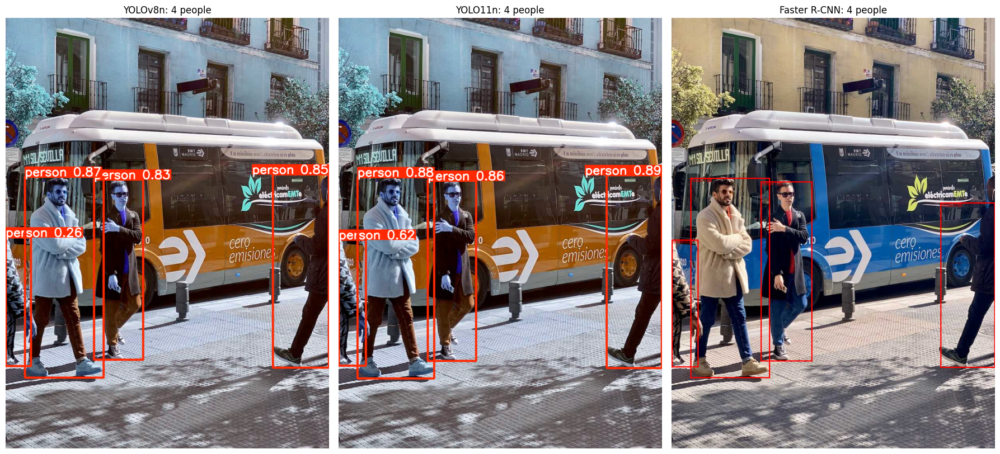

In [5]:

# Cell 5: Visualize detections from all three models

import matplotlib.pyplot as plt

# YOLOv8n
yolov8_image = results_v8[0].plot()

# YOLO11n
yolo11_image = results_11[0].plot()

# Faster R-CNN
faster_image = sample_image.copy()

from PIL import ImageDraw

draw = ImageDraw.Draw(faster_image)

for box, label, score in zip(
    faster_boxes,
    faster_labels,
    faster_scores
):
    if label == 1 and score >= 0.5:
        x1, y1, x2, y2 = box.cpu().numpy()

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=3
        )

        draw.text(
            (x1, y1),
            f"Person {score:.2f}",
            fill="red"
        )

# Display results
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

axes[0].imshow(yolov8_image)
axes[0].set_title(f"YOLOv8n: {count_v8} people")

axes[1].imshow(yolo11_image)
axes[1].set_title(f"YOLO11n: {count_11} people")

axes[2].imshow(faster_image)
axes[2].set_title(f"Faster R-CNN: {count_faster} people")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

# Cell 6: Create evaluation dataset structure

import os
import pandas as pd

# Create folders
os.makedirs("lane_radar/data/eval_images", exist_ok=True)
os.makedirs("lane_radar/results", exist_ok=True)

# Create an empty evaluation dataset
dataset = pd.DataFrame(columns=[
    "image_path",
    "actual_people"
])

dataset.to_csv(
    "lane_radar/data/eval_dataset.csv",
    index=False
)

print("Evaluation dataset folders created successfully!")

print("\nDataset columns:")
print(dataset.columns.tolist())

print("\nImage folder:")
print("lane_radar/data/eval_images/")


Evaluation dataset folders created successfully!

Dataset columns:
['image_path', 'actual_people']

Image folder:
lane_radar/data/eval_images/


In [7]:

# Cell 7: Collect supermarket queue image candidates

import os
import subprocess
import shutil
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Source repository containing supermarket queue examples
repo_url = "https://github.com/FaizanAli7005/supermarket-queue-monitor.git"
repo_folder = "/content/supermarket-queue-monitor"

# Download repository
if not os.path.exists(repo_folder):
    subprocess.run(
        ["git", "clone", "--depth", "1", repo_url, repo_folder],
        check=True
    )

# Find image files
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

candidate_images = []

for root, dirs, files in os.walk(repo_folder):
    for file in files:
        if Path(file).suffix.lower() in image_extensions:
            candidate_images.append(os.path.join(root, file))

print("Images found:", len(candidate_images))

# Copy up to 20 images
output_folder = "lane_radar/data/eval_images"
os.makedirs(output_folder, exist_ok=True)

selected_images = candidate_images[:20]

for i, source_path in enumerate(selected_images, start=1):
    destination_path = os.path.join(
        output_folder,
        f"lane_{i:02d}.jpg"
    )

    image = Image.open(source_path).convert("RGB")
    image.save(destination_path)

print("Images copied:", len(selected_images))


Images found: 6
Images copied: 6


In [9]:

# Lane Radar - Cell 7
# Download supermarket checkout and queue image candidates
# Source: Wikimedia Commons

import requests
import os
import time
import pandas as pd
from PIL import Image
from io import BytesIO

API_URL = "https://commons.wikimedia.org/w/api.php"

image_folder = "lane_radar/data/eval_images"
os.makedirs(image_folder, exist_ok=True)

headers = {
    "User-Agent": "LaneRadarEvaluation/1.0 (student project)"
}

# Search categories relevant to supermarket queues
categories = [
    "Category:Shop queues",
    "Category:Supermarket checkouts",
    "Category:Supermarket checkouts in the United States",
    "Category:Shop checkouts in the United States"
]

# Collect image filenames
all_files = {}

for category in categories:

    params = {
        "action": "query",
        "format": "json",
        "list": "categorymembers",
        "cmtitle": category,
        "cmtype": "file",
        "cmlimit": 200
    }

    response = requests.get(
        API_URL,
        params=params,
        headers=headers,
        timeout=30
    )

    response.raise_for_status()

    files = response.json().get(
        "query", {}
    ).get("categorymembers", [])

    for file in files:
        all_files[file["title"]] = file["title"]

print("Unique files found:", len(all_files))

# Keep filenames that are relevant to checkout or queue scenes
keywords = [
    "queue", "line", "checkout", "cashier",
    "grocery", "supermarket", "shopping",
    "shopper", "customer"
]

candidate_titles = [
    title for title in all_files
    if any(word in title.lower() for word in keywords)
]

print("Relevant filename candidates:", len(candidate_titles))

# Download images
downloaded = []

for title in candidate_titles:

    if len(downloaded) >= 20:
        break

    params = {
        "action": "query",
        "format": "json",
        "titles": title,
        "prop": "imageinfo",
        "iiprop": "url|extmetadata",
        "iiurlwidth": 1000
    }

    try:
        response = requests.get(
            API_URL,
            params=params,
            headers=headers,
            timeout=30
        )

        response.raise_for_status()

        pages = response.json().get(
            "query", {}
        ).get("pages", {})

        page = next(iter(pages.values()))
        image_info = page.get("imageinfo", [])

        if not image_info:
            continue

        info = image_info[0]
        image_url = info.get("thumburl", info.get("url"))

        image_response = requests.get(
            image_url,
            headers=headers,
            timeout=30
        )

        image_response.raise_for_status()

        image = Image.open(
            BytesIO(image_response.content)
        ).convert("RGB")

        # Skip very small images
        if image.width < 300 or image.height < 200:
            continue

        filename = f"lane_{len(downloaded)+1:02d}.jpg"

        image.save(
            os.path.join(image_folder, filename),
            quality=90
        )

        metadata = info.get("extmetadata", {})

        downloaded.append({
            "filename": filename,
            "source_title": title,
            "source_url": image_url,
            "license": metadata.get(
                "LicenseShortName", {}
            ).get("value", "Unknown"),
            "artist": metadata.get(
                "Artist", {}
            ).get("value", "Unknown")
        })

        print(
            f"Downloaded {filename}: {title}"
        )

        time.sleep(0.3)

    except Exception as error:
        print("Skipped:", title, "|", error)

# Save source attribution
source_df = pd.DataFrame(downloaded)

source_df.to_csv(
    "lane_radar/data/image_sources.csv",
    index=False
)

print("\n================================")
print("TOTAL IMAGES DOWNLOADED:", len(downloaded))
print("================================")

if len(downloaded) < 20:
    print("More suitable images may be needed.")
else:
    print("20 image candidates collected!")


Unique files found: 118
Relevant filename candidates: 56
Downloaded lane_01.jpg: File:024-02 - free download photo of people shopping and walking with umbrellas in the shopping street Steenweg in Utrecht city on a rainy day with lighting shop shop windows. Street photography in high resolution photos by Fons Heijnsbroek.tif
Downloaded lane_02.jpg: File:2024 - free download photo of Utrecht old city; a family and other city people are shopping on a grey saterday in the shop street Steenweg - full of shop windows. Street photography; high resolution photo Fons Heijnsbroek, Netherlands.tif
Downloaded lane_03.jpg: File:La queue à la boucherie (siège de Paris) (NYPL b13472280-483375).jpg
Downloaded lane_04.jpg: File:La queue à la boucherie (siège de Paris) (NYPL b13472280-483375).tiff
Downloaded lane_05.jpg: File:Ian Art Photography - Italy 100 people queuing at a supermarket during coronavirus outbreak mar-2020.jpg
Downloaded lane_06.jpg: File:MV Costco food court queue.jpg
Downloaded lane

In [3]:
from google.colab import files
import os
import pandas as pd

# Dataset folder
image_folder = "/content/lane_radar/data/eval_images"
os.makedirs(image_folder, exist_ok=True)

# Upload your 13 downloaded images
uploaded = files.upload()

# Save uploaded images without overwriting existing images
for filename, content in uploaded.items():
    name, ext = os.path.splitext(filename)
    save_name = filename
    counter = 1

    while os.path.exists(os.path.join(image_folder, save_name)):
        save_name = f"{name}_{counter}{ext}"
        counter += 1

    with open(os.path.join(image_folder, save_name), "wb") as f:
        f.write(content)

    print("Saved:", save_name)

# Display total dataset images
image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("\nTotal images in dataset:", len(image_files))

Saving Busy Supermarket Checkout Lane 5.png to Busy Supermarket Checkout Lane 5 (1).png
Saving Supermarket Checkout Queue.png to Supermarket Checkout Queue.png
Saving Supermarket Checkout Queue-1.png to Supermarket Checkout Queue-1.png
Saving StockCake-Supermarket_Checkout_Line-635340-small.jpg to StockCake-Supermarket_Checkout_Line-635340-small.jpg
Saving StockCake-Supermarket_Checkout_Line-998029-small.jpg to StockCake-Supermarket_Checkout_Line-998029-small.jpg
Saving StockCake-Grocery_Checkout_Line-998031-medium.jpg to StockCake-Grocery_Checkout_Line-998031-medium.jpg
Saving sm img.webp to sm img.webp
Saving IMG_2209.webp to IMG_2209.webp
Saving defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg to defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
Saving citymarket-atd-031916.jpg to citymarket-atd-031916.jpg
Saving boston-public-library-bnULe-SMWiI-unsplash.jpg to boston-public-library-bnULe-SMWiI-unsplash.jpg
Saving rumman-amin-1SAjPs77I5Q-unsplash.jpg to rumman-amin-1SAjPs77I5Q-u

In [4]:
import os

image_folder = "/content/lane_radar/data/eval_images"

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Total images:", len(image_files))
print("\nImages found:")

for f in image_files:
    print(f)

Total images: 15

Images found:
Supermarket Checkout Queue.png
StockCake-Grocery_Checkout_Line-998031-medium.jpg
sm img.webp
Busy Supermarket Checkout Lane 5 (1).png
Supermarket Checkout Queue-1.png
brittani-burns-pEu_jnyi2c4-unsplash.jpg
citymarket-atd-031916.jpg
Busy Supermarket Checkout Lane 5.png
StockCake-Supermarket_Checkout_Line-635340-small.jpg
rumman-amin-1SAjPs77I5Q-unsplash (1).jpg
boston-public-library-bnULe-SMWiI-unsplash.jpg
rumman-amin-1SAjPs77I5Q-unsplash.jpg
StockCake-Supermarket_Checkout_Line-998029-small.jpg
defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
IMG_2209.webp


In [5]:
import os

image_folder = "/content/lane_radar/data/eval_images"

for filename in sorted(os.listdir(image_folder)):
    print(filename)

Busy Supermarket Checkout Lane 5 (1).png
Busy Supermarket Checkout Lane 5.png
IMG_2209.webp
StockCake-Grocery_Checkout_Line-998031-medium.jpg
StockCake-Supermarket_Checkout_Line-635340-small.jpg
StockCake-Supermarket_Checkout_Line-998029-small.jpg
Supermarket Checkout Queue-1.png
Supermarket Checkout Queue.png
boston-public-library-bnULe-SMWiI-unsplash.jpg
brittani-burns-pEu_jnyi2c4-unsplash.jpg
citymarket-atd-031916.jpg
defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
rumman-amin-1SAjPs77I5Q-unsplash (1).jpg
rumman-amin-1SAjPs77I5Q-unsplash.jpg
sm img.webp


In [6]:
import os
import hashlib

image_folder = "/content/lane_radar/data/eval_images"

seen_hashes = set()
removed = []

for filename in sorted(os.listdir(image_folder)):
    path = os.path.join(image_folder, filename)

    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
        continue

    with open(path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

    if file_hash in seen_hashes:
        os.remove(path)
        removed.append(filename)
    else:
        seen_hashes.add(file_hash)

print("Duplicates removed:", removed)
print("Unique images remaining:", len(seen_hashes))

Duplicates removed: ['Busy Supermarket Checkout Lane 5.png', 'rumman-amin-1SAjPs77I5Q-unsplash.jpg']
Unique images remaining: 13


In [7]:
import os

for root, dirs, files in os.walk("/content"):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if image_files:
        print("\nFolder:", root)
        print("Images:", len(image_files))
        for f in image_files[:15]:
            print(" -", f)


Folder: /content
Images: 15
 - Supermarket Checkout Queue.png
 - StockCake-Grocery_Checkout_Line-998031-medium.jpg
 - sm img.webp
 - Busy Supermarket Checkout Lane 5 (1).png
 - Supermarket Checkout Queue-1.png
 - brittani-burns-pEu_jnyi2c4-unsplash.jpg
 - citymarket-atd-031916.jpg
 - Busy Supermarket Checkout Lane 5.png
 - StockCake-Supermarket_Checkout_Line-635340-small.jpg
 - rumman-amin-1SAjPs77I5Q-unsplash (1).jpg
 - boston-public-library-bnULe-SMWiI-unsplash.jpg
 - rumman-amin-1SAjPs77I5Q-unsplash.jpg
 - StockCake-Supermarket_Checkout_Line-998029-small.jpg
 - defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
 - IMG_2209.webp

Folder: /content/lane_radar/data/eval_images
Images: 13
 - Supermarket Checkout Queue.png
 - StockCake-Grocery_Checkout_Line-998031-medium.jpg
 - sm img.webp
 - Busy Supermarket Checkout Lane 5 (1).png
 - Supermarket Checkout Queue-1.png
 - brittani-burns-pEu_jnyi2c4-unsplash.jpg
 - citymarket-atd-031916.jpg
 - StockCake-Supermarket_Checkout_Line-635340-sma

In [8]:
from google.colab import files
import os

image_folder = "/content/lane_radar/data/eval_images"
os.makedirs(image_folder, exist_ok=True)

uploaded = files.upload()

for filename, content in uploaded.items():
    name, ext = os.path.splitext(filename)
    save_name = filename
    counter = 1

    while os.path.exists(os.path.join(image_folder, save_name)):
        save_name = f"{name}_{counter}{ext}"
        counter += 1

    with open(os.path.join(image_folder, save_name), "wb") as f:
        f.write(content)

    print("Uploaded:", save_name)

print("\nTotal images in dataset:",
      len([f for f in os.listdir(image_folder)
           if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))]))

Saving Supermarket Checkout Queue.png to Supermarket Checkout Queue (1).png
Saving Busy Supermarket Checkout Lane.png to Busy Supermarket Checkout Lane.png
Saving vlcsnap-2026-08-21-09h41m20s589.webp to vlcsnap-2026-08-21-09h41m20s589.webp
Saving 2ADCGEDSPFFCVKR2KZTFNE3P6M.avif to 2ADCGEDSPFFCVKR2KZTFNE3P6M.avif
Saving images.jpg to images.jpg
Saving 474624280_10228153000916349_2449729908729899898_n.jpg to 474624280_10228153000916349_2449729908729899898_n.jpg
Saving 180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.avif to 180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.avif
Uploaded: Supermarket Checkout Queue (1).png
Uploaded: Busy Supermarket Checkout Lane.png
Uploaded: vlcsnap-2026-08-21-09h41m20s589.webp
Uploaded: 2ADCGEDSPFFCVKR2KZTFNE3P6M.avif
Uploaded: images.jpg
Uploaded: 474624280_10228153000916349_2449729908729899898_n.jpg
Uploaded: 180630515-people-stand

In [9]:
import os

image_folder = "/content/lane_radar/data/eval_images"

image_files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Current total:", len(image_files))
print("\nAll image filenames:")

for filename in image_files:
    print(filename)

print("\nFiles selected in the last upload:")
for filename in uploaded.keys():
    print(filename)

Current total: 18

All image filenames:
474624280_10228153000916349_2449729908729899898_n.jpg
Busy Supermarket Checkout Lane 5 (1).png
Busy Supermarket Checkout Lane.png
IMG_2209.webp
StockCake-Grocery_Checkout_Line-998031-medium.jpg
StockCake-Supermarket_Checkout_Line-635340-small.jpg
StockCake-Supermarket_Checkout_Line-998029-small.jpg
Supermarket Checkout Queue (1).png
Supermarket Checkout Queue-1.png
Supermarket Checkout Queue.png
boston-public-library-bnULe-SMWiI-unsplash.jpg
brittani-burns-pEu_jnyi2c4-unsplash.jpg
citymarket-atd-031916.jpg
defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
images.jpg
rumman-amin-1SAjPs77I5Q-unsplash (1).jpg
sm img.webp
vlcsnap-2026-08-21-09h41m20s589.webp

Files selected in the last upload:
Supermarket Checkout Queue (1).png
Busy Supermarket Checkout Lane.png
vlcsnap-2026-08-21-09h41m20s589.webp
2ADCGEDSPFFCVKR2KZTFNE3P6M.avif
images.jpg
474624280_10228153000916349_2449729908729899898_n.jpg
180630515-people-standing-in-queue-in-supermarket-custom

In [10]:
import os

image_folder = "/content/lane_radar/data/eval_images"

image_extensions = (".jpg", ".jpeg", ".png", ".webp", ".avif")

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith(image_extensions)
]

print("Total images in dataset:", len(image_files))

for filename in sorted(image_files):
    print(filename)

Total images in dataset: 20
180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.avif
2ADCGEDSPFFCVKR2KZTFNE3P6M.avif
474624280_10228153000916349_2449729908729899898_n.jpg
Busy Supermarket Checkout Lane 5 (1).png
Busy Supermarket Checkout Lane.png
IMG_2209.webp
StockCake-Grocery_Checkout_Line-998031-medium.jpg
StockCake-Supermarket_Checkout_Line-635340-small.jpg
StockCake-Supermarket_Checkout_Line-998029-small.jpg
Supermarket Checkout Queue (1).png
Supermarket Checkout Queue-1.png
Supermarket Checkout Queue.png
boston-public-library-bnULe-SMWiI-unsplash.jpg
brittani-burns-pEu_jnyi2c4-unsplash.jpg
citymarket-atd-031916.jpg
defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
images.jpg
rumman-amin-1SAjPs77I5Q-unsplash (1).jpg
sm img.webp
vlcsnap-2026-08-21-09h41m20s589.webp


In [11]:
from PIL import Image
import os

image_folder = "/content/lane_radar/data/eval_images"

for filename in os.listdir(image_folder):
    if filename.lower().endswith(".avif"):
        image_path = os.path.join(image_folder, filename)

        img = Image.open(image_path).convert("RGB")

        new_filename = os.path.splitext(filename)[0] + ".jpg"
        new_path = os.path.join(image_folder, new_filename)

        img.save(new_path, "JPEG", quality=95)

        print("Converted:", filename, "->", new_filename)

print("AVIF conversion completed!")

Converted: 2ADCGEDSPFFCVKR2KZTFNE3P6M.avif -> 2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg
Converted: 180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.avif -> 180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.jpg
AVIF conversion completed!


Total images: 20


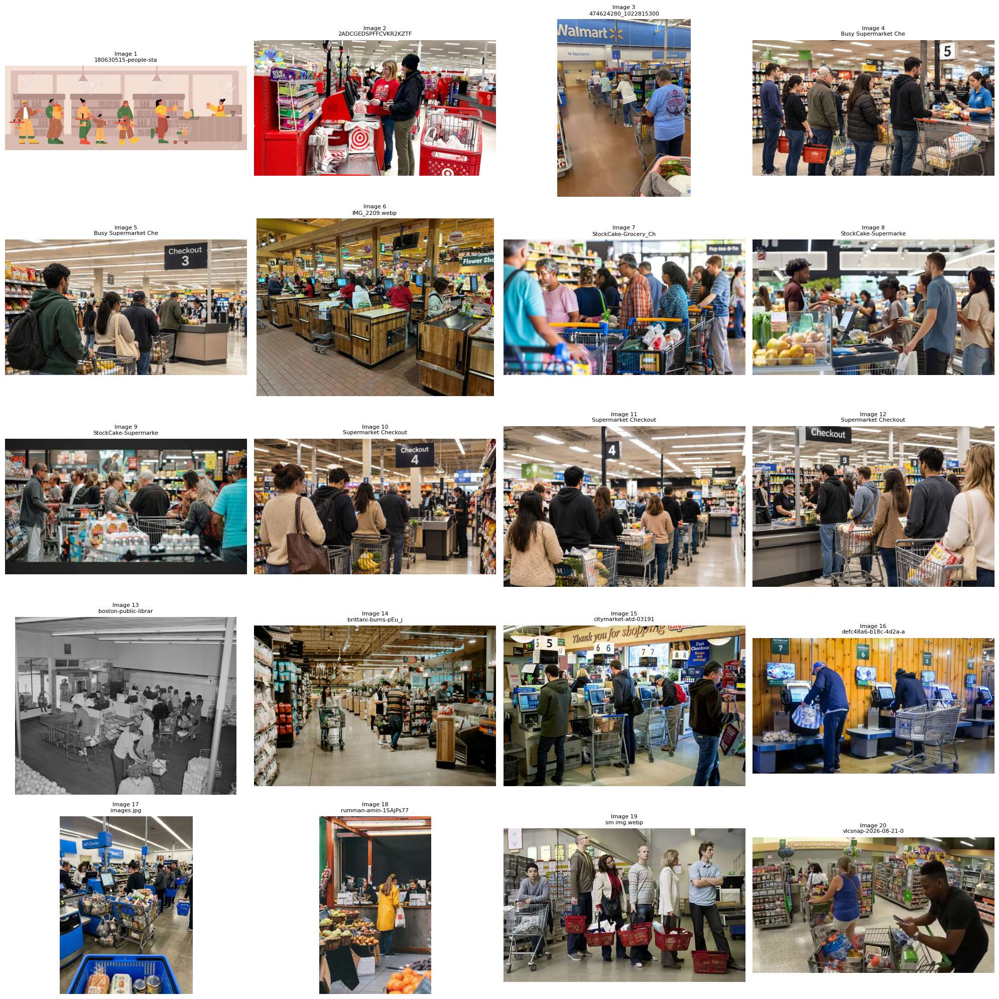

In [12]:
import os
import matplotlib.pyplot as plt
from PIL import Image

image_folder = "/content/lane_radar/data/eval_images"

image_files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Total images:", len(image_files))

plt.figure(figsize=(20, 20))

for i, filename in enumerate(image_files):
    img = Image.open(os.path.join(image_folder, filename)).convert("RGB")

    plt.subplot(5, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i+1}\n{filename[:20]}", fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
import os
import pandas as pd

image_folder = "/content/lane_radar/data/eval_images"
csv_path = "/content/lane_radar/data/eval_dataset.csv"

image_files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

df = pd.DataFrame({
    "image_path": [
        os.path.join(image_folder, filename)
        for filename in image_files
    ],
    "actual_people": [""] * len(image_files)
})

df.to_csv(csv_path, index=False)

print("CSV created:", csv_path)
print("Total images:", len(df))

display(df)

CSV created: /content/lane_radar/data/eval_dataset.csv
Total images: 20


,image_path,actual_people
0,/content/lane_radar/data/eval_images/180630515...,
1,/content/lane_radar/data/eval_images/2ADCGEDSP...,
2,/content/lane_radar/data/eval_images/474624280...,
3,/content/lane_radar/data/eval_images/Busy Supe...,
4,/content/lane_radar/data/eval_images/Busy Supe...,
5,/content/lane_radar/data/eval_images/IMG_2209....,
6,/content/lane_radar/data/eval_images/StockCake...,
7,/content/lane_radar/data/eval_images/StockCake...,
8,/content/lane_radar/data/eval_images/StockCake...,
9,/content/lane_radar/data/eval_images/Supermark...,



Image 1 of 20
Filename: 180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.jpg


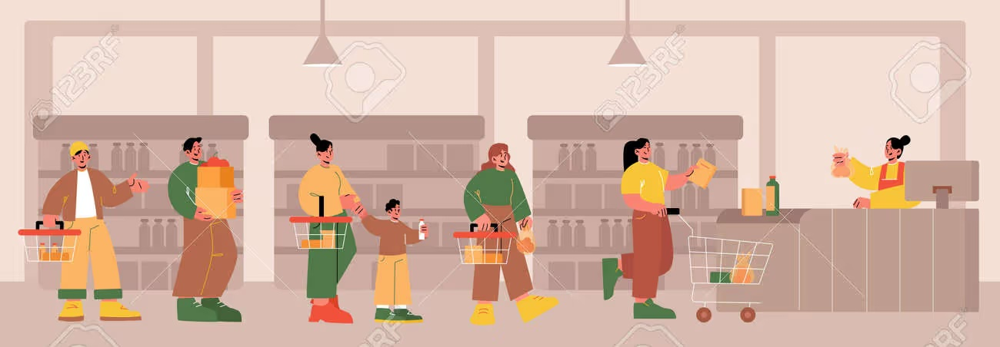

KeyboardInterrupt: Interrupted by user

In [14]:
import os
import pandas as pd
from PIL import Image
from IPython.display import display

image_folder = "/content/lane_radar/data/eval_images"
csv_path = "/content/lane_radar/data/eval_dataset.csv"

image_files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

df = pd.read_csv(csv_path)

for i, filename in enumerate(image_files):
    image_path = os.path.join(image_folder, filename)

    print(f"\nImage {i+1} of {len(image_files)}")
    print("Filename:", filename)

    img = Image.open(image_path).convert("RGB")
    display(img)

    count = int(input("Enter the actual number of people visible: "))

    df.loc[df["image_path"] == image_path, "actual_people"] = count

    df.to_csv(csv_path, index=False)

print("\nGround-truth annotation completed!")
display(df)

In [15]:
import os
import pandas as pd
import ipywidgets as widgets
from PIL import Image
from IPython.display import display

image_folder = "/content/lane_radar/data/eval_images"
csv_path = "/content/lane_radar/data/eval_dataset.csv"

image_files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

df = pd.read_csv(csv_path)

current_index = 0

image_output = widgets.Output()
count_box = widgets.IntText(
    value=0,
    description="People count:",
    style={"description_width": "initial"}
)

next_button = widgets.Button(
    description="Save & Next",
    button_style="success"
)

status = widgets.Label()

def show_image():
    with image_output:
        image_output.clear_output(wait=True)

        if current_index < len(image_files):
            filename = image_files[current_index]
            image_path = os.path.join(image_folder, filename)

            print(f"Image {current_index + 1} of {len(image_files)}")
            print(filename)

            display(Image.open(image_path).convert("RGB"))

            status.value = "Enter the people count, then click Save & Next."
        else:
            print("All images annotated!")
            status.value = "Annotation completed."

def save_next(button):
    global current_index

    if current_index >= len(image_files):
        return

    filename = image_files[current_index]
    image_path = os.path.join(image_folder, filename)

    df.loc[df["image_path"] == image_path, "actual_people"] = count_box.value

    df.to_csv(csv_path, index=False)

    current_index += 1
    count_box.value = 0

    show_image()

next_button.on_click(save_next)

display(image_output, count_box, next_button, status)

show_image()

Output()

IntText(value=0, description='People count:', style=DescriptionStyle(description_width='initial'))

Button(button_style='success', description='Save & Next', style=ButtonStyle())

Label(value='')

In [16]:
import pandas as pd

csv_path = "/content/lane_radar/data/eval_dataset.csv"

df = pd.read_csv(csv_path)

print("Total images:", len(df))
print("Missing counts:", df["actual_people"].isna().sum())

display(df)

Total images: 20
Missing counts: 0


,image_path,actual_people
0,/content/lane_radar/data/eval_images/180630515...,7.0
1,/content/lane_radar/data/eval_images/2ADCGEDSP...,2.0
2,/content/lane_radar/data/eval_images/474624280...,4.0
3,/content/lane_radar/data/eval_images/Busy Supe...,6.0
4,/content/lane_radar/data/eval_images/Busy Supe...,5.0
5,/content/lane_radar/data/eval_images/IMG_2209....,12.0
6,/content/lane_radar/data/eval_images/StockCake...,11.0
7,/content/lane_radar/data/eval_images/StockCake...,7.0
8,/content/lane_radar/data/eval_images/StockCake...,12.0
9,/content/lane_radar/data/eval_images/Supermark...,5.0


In [17]:
import pandas as pd

csv_path = "/content/lane_radar/data/eval_dataset.csv"

df = pd.read_csv(csv_path)

print("Total images:", len(df))
print("Missing people counts:", df["actual_people"].isna().sum())

print("\nGround-truth dataset:")
display(df)

if len(df) == 20 and df["actual_people"].isna().sum() == 0:
    print("\nAll 20 images are annotated successfully!")
else:
    print("\nPlease check for missing annotations.")

Total images: 20
Missing people counts: 0

Ground-truth dataset:


,image_path,actual_people
0,/content/lane_radar/data/eval_images/180630515...,7.0
1,/content/lane_radar/data/eval_images/2ADCGEDSP...,2.0
2,/content/lane_radar/data/eval_images/474624280...,4.0
3,/content/lane_radar/data/eval_images/Busy Supe...,6.0
4,/content/lane_radar/data/eval_images/Busy Supe...,5.0
5,/content/lane_radar/data/eval_images/IMG_2209....,12.0
6,/content/lane_radar/data/eval_images/StockCake...,11.0
7,/content/lane_radar/data/eval_images/StockCake...,7.0
8,/content/lane_radar/data/eval_images/StockCake...,12.0
9,/content/lane_radar/data/eval_images/Supermark...,5.0



All 20 images are annotated successfully!


In [19]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [20]:
import os
import time
import pandas as pd
import numpy as np
import torch

from ultralytics import YOLO
from PIL import Image
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

# --------------------------------------------------
# 1. Load annotated dataset
# --------------------------------------------------

csv_path = "/content/lane_radar/data/eval_dataset.csv"

df = pd.read_csv(csv_path)
df["actual_people"] = pd.to_numeric(
    df["actual_people"], errors="coerce"
)

df = df.dropna(subset=["actual_people"]).copy()
df["actual_people"] = df["actual_people"].astype(int)

print("Images for evaluation:", len(df))

# --------------------------------------------------
# 2. Load models
# --------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

yolov8 = YOLO("yolov8n.pt")
yolo11 = YOLO("yolo11n.pt")

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
faster_rcnn = fasterrcnn_resnet50_fpn(weights=weights)
faster_rcnn = faster_rcnn.to(device)
faster_rcnn.eval()

# --------------------------------------------------
# 3. Evaluation function
# --------------------------------------------------

results = []

def evaluate_model(model_name, actual_counts, predicted_counts, times):

    actual_counts = np.array(actual_counts)
    predicted_counts = np.array(predicted_counts)

    errors = predicted_counts - actual_counts

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    exact_match = np.mean(errors == 0) * 100
    within_one = np.mean(np.abs(errors) <= 1) * 100

    avg_time = np.mean(times)

    return {
        "Model": model_name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "Exact Match (%)": round(exact_match, 2),
        "Within ±1 (%)": round(within_one, 2),
        "Avg Inference Time (s)": round(avg_time, 4)
    }

# --------------------------------------------------
# 4. Evaluate YOLOv8n
# --------------------------------------------------

actual_counts = df["actual_people"].tolist()

yolov8_predictions = []
yolov8_times = []

for image_path in df["image_path"]:

    start = time.perf_counter()

    prediction = yolov8.predict(
        source=image_path,
        classes=[0],
        conf=0.25,
        verbose=False
    )[0]

    predicted_count = len(prediction.boxes)

    yolov8_predictions.append(predicted_count)

    yolov8_times.append(time.perf_counter() - start)

print("YOLOv8n evaluation completed!")

# --------------------------------------------------
# 5. Evaluate YOLO11n
# --------------------------------------------------

yolo11_predictions = []
yolo11_times = []

for image_path in df["image_path"]:

    start = time.perf_counter()

    prediction = yolo11.predict(
        source=image_path,
        classes=[0],
        conf=0.25,
        verbose=False
    )[0]

    predicted_count = len(prediction.boxes)

    yolo11_predictions.append(predicted_count)

    yolo11_times.append(time.perf_counter() - start)

print("YOLO11n evaluation completed!")

# --------------------------------------------------
# 6. Evaluate Faster R-CNN
# --------------------------------------------------

faster_predictions = []
faster_times = []

for image_path in df["image_path"]:

    image = Image.open(image_path).convert("RGB")

    image_tensor = weights.transforms()(image).to(device)

    start = time.perf_counter()

    with torch.no_grad():
        prediction = faster_rcnn([image_tensor])[0]

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    # COCO class 1 = person
    person_mask = (
        (prediction["labels"] == 1) &
        (prediction["scores"] >= 0.25)
    )

    predicted_count = int(person_mask.sum().item())

    faster_predictions.append(predicted_count)
    faster_times.append(elapsed)

print("Faster R-CNN evaluation completed!")

# --------------------------------------------------
# 7. Compare models
# --------------------------------------------------

comparison = pd.DataFrame([
    evaluate_model(
        "YOLOv8n",
        actual_counts,
        yolov8_predictions,
        yolov8_times
    ),
    evaluate_model(
        "YOLO11n",
        actual_counts,
        yolo11_predictions,
        yolo11_times
    ),
    evaluate_model(
        "Faster R-CNN ResNet50 FPN",
        actual_counts,
        faster_predictions,
        faster_times
    )
])

print("\nMODEL COMPARISON RESULTS")
display(comparison)

# --------------------------------------------------
# 8. Save predictions
# --------------------------------------------------

df["YOLOv8n_predicted"] = yolov8_predictions
df["YOLO11n_predicted"] = yolo11_predictions
df["FasterRCNN_predicted"] = faster_predictions

results_path = "/content/lane_radar/results/model_evaluation.csv"

df.to_csv(results_path, index=False)
comparison.to_csv(
    "/content/lane_radar/results/model_comparison.csv",
    index=False
)

print("\nResults saved successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Images for evaluation: 20
Device: cuda
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:02<00:00, 81.1MB/s]


YOLOv8n evaluation completed!
YOLO11n evaluation completed!
Faster R-CNN evaluation completed!

MODEL COMPARISON RESULTS


,Model,MAE,RMSE,Exact Match (%),Within ±1 (%),Avg Inference Time (s)
0,YOLOv8n,2.60,3.421,20.0,45.0,0.3191
1,YOLO11n,2.40,2.966,15.0,30.0,0.1209
2,Faster R-CNN ResNet50 FPN,7.45,9.521,5.0,20.0,0.1664


OSError: Cannot save file into a non-existent directory: '/content/lane_radar/results'

In [21]:
import os

# Create the missing results folder
os.makedirs("/content/lane_radar/results", exist_ok=True)

# Save the evaluation results
df.to_csv(
    "/content/lane_radar/results/model_evaluation.csv",
    index=False
)

comparison.to_csv(
    "/content/lane_radar/results/model_comparison.csv",
    index=False
)

print("Both result files saved successfully!")

Both result files saved successfully!


In [22]:
import pandas as pd

# Calculate absolute counting errors
df["YOLOv8n_Error"] = abs(
    df["YOLOv8n_predicted"] - df["actual_people"]
)

df["YOLO11n_Error"] = abs(
    df["YOLO11n_predicted"] - df["actual_people"]
)

df["FasterRCNN_Error"] = abs(
    df["FasterRCNN_predicted"] - df["actual_people"]
)

# Display the 5 images with the largest YOLO11n errors
worst_cases = df.sort_values(
    by="YOLO11n_Error",
    ascending=False
)

display(
    worst_cases[
        [
            "image_path",
            "actual_people",
            "YOLOv8n_predicted",
            "YOLOv8n_Error",
            "YOLO11n_predicted",
            "YOLO11n_Error",
            "FasterRCNN_predicted",
            "FasterRCNN_Error"
        ]
    ].head(5)
)

,image_path,actual_people,YOLOv8n_predicted,YOLOv8n_Error,YOLO11n_predicted,YOLO11n_Error,FasterRCNN_predicted,FasterRCNN_Error
12,/content/lane_radar/data/eval_images/boston-pu...,22,16,6,16,6,29,7
5,/content/lane_radar/data/eval_images/IMG_2209....,12,8,4,6,6,22,10
1,/content/lane_radar/data/eval_images/2ADCGEDSP...,2,9,7,6,4,13,11
16,/content/lane_radar/data/eval_images/images.jpg,15,10,5,11,4,20,5
18,/content/lane_radar/data/eval_images/sm img.webp,6,8,2,10,4,11,5


Image: boston-public-library-bnULe-SMWiI-unsplash.jpg
YOLO11n detected: 16 people


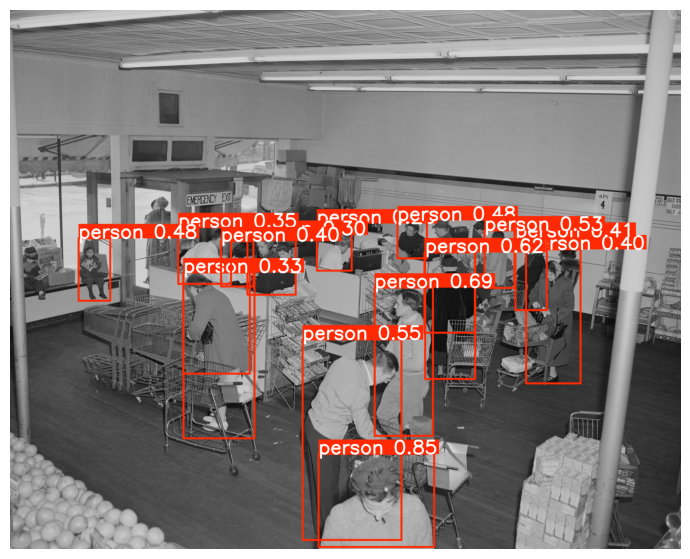

Image: IMG_2209.webp
YOLO11n detected: 6 people


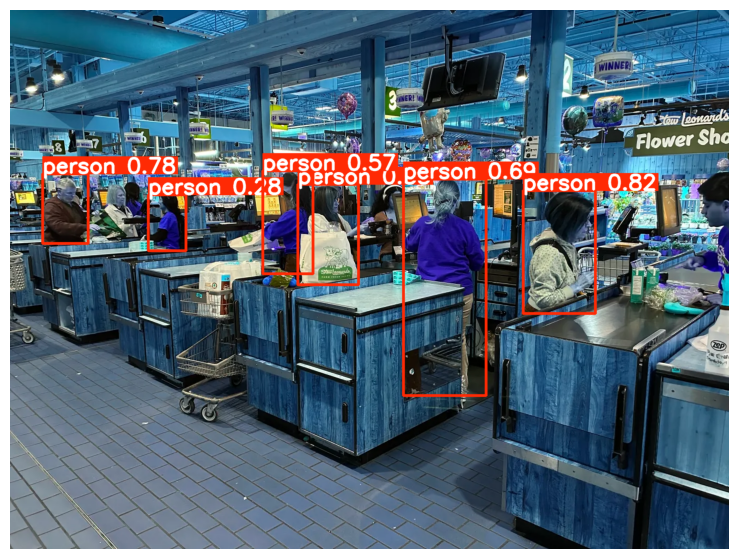

Image: 2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg
YOLO11n detected: 6 people


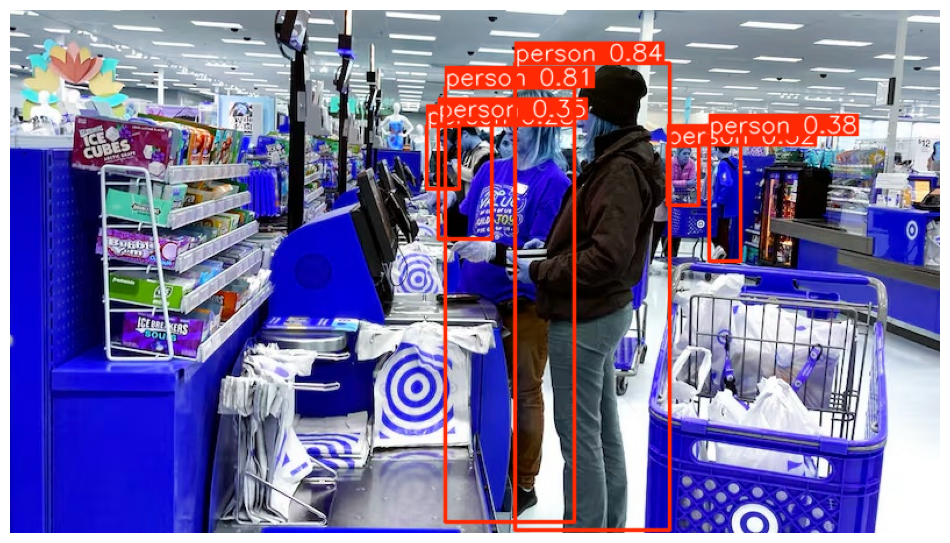

In [23]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

error_images = [
    "/content/lane_radar/data/eval_images/boston-public-library-bnULe-SMWiI-unsplash.jpg",
    "/content/lane_radar/data/eval_images/IMG_2209.webp",
    "/content/lane_radar/data/eval_images/2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg"
]

for image_path in error_images:

    result = model.predict(
        source=image_path,
        classes=[0],
        conf=0.25,
        verbose=False
    )[0]

    detected_count = len(result.boxes)

    print("Image:", image_path.split("/")[-1])
    print("YOLO11n detected:", detected_count, "people")

    plt.figure(figsize=(12, 7))
    plt.imshow(result.plot())
    plt.axis("off")
    plt.show()

In [24]:
import os
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image

# Select the model you want to evaluate:
# "YOLOv8n", "YOLO11n", or "Faster R-CNN"

MODEL_NAME = "YOLO11n"

def run_evaluation(model_name, dataset):

    actual_counts = dataset["actual_people"].astype(int).tolist()
    predicted_counts = []
    inference_times = []

    for image_path in dataset["image_path"]:

        start = time.perf_counter()

        if model_name == "YOLOv8n":
            prediction = yolov8.predict(
                source=image_path,
                classes=[0],
                conf=0.25,
                verbose=False
            )[0]

            predicted_count = len(prediction.boxes)

        elif model_name == "YOLO11n":
            prediction = yolo11.predict(
                source=image_path,
                classes=[0],
                conf=0.25,
                verbose=False
            )[0]

            predicted_count = len(prediction.boxes)

        elif model_name == "Faster R-CNN":

            image = Image.open(image_path).convert("RGB")
            image_tensor = weights.transforms()(image).to(device)

            with torch.no_grad():
                prediction = faster_rcnn([image_tensor])[0]

            predicted_count = int(
                (
                    (prediction["labels"] == 1) &
                    (prediction["scores"] >= 0.25)
                ).sum().item()
            )

        else:
            raise ValueError("Invalid model name.")

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        predicted_counts.append(predicted_count)
        inference_times.append(elapsed)

    errors = np.array(predicted_counts) - np.array(actual_counts)

    results = {
        "Model": model_name,
        "MAE": round(np.mean(np.abs(errors)), 3),
        "RMSE": round(np.sqrt(np.mean(errors ** 2)), 3),
        "Exact Match (%)": round(np.mean(errors == 0) * 100, 2),
        "Within ±1 (%)": round(np.mean(np.abs(errors) <= 1) * 100, 2),
        "Avg Inference Time (s)": round(np.mean(inference_times), 4)
    }

    return results


# Run the selected model
selected_result = run_evaluation(MODEL_NAME, df)

display(pd.DataFrame([selected_result]))

# Save the selected model's evaluation
os.makedirs("/content/lane_radar/results", exist_ok=True)

pd.DataFrame([selected_result]).to_csv(
    f"/content/lane_radar/results/{MODEL_NAME.replace(' ', '_')}_evaluation.csv",
    index=False
)

print("Selected model evaluation saved!")

,Model,MAE,RMSE,Exact Match (%),Within ±1 (%),Avg Inference Time (s)
0,YOLO11n,2.4,2.966,15.0,30.0,0.1164


Selected model evaluation saved!


In [26]:
import os

project_folder = "/content/lane_radar"
os.makedirs(project_folder, exist_ok=True)

readme = """
# Lane Radar
## Smart Queue and Checkout Time Estimation

Lane Radar is a computer vision project that estimates the number
of people waiting at supermarket checkout lanes.

### Models Evaluated
- YOLOv8n
- YOLO11n
- Faster R-CNN ResNet50 FPN

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Exact Match Accuracy
- Accuracy Within ±1 Person
- Average Inference Time

### Dataset
The evaluation dataset contains 20 supermarket checkout images
with manually annotated ground-truth person counts.

### Technologies
Python, Google Colab, PyTorch, Ultralytics YOLO, OpenCV

### Running the Project
Run the notebook cells in order to evaluate the models
and compare their performance.
"""

readme_path = os.path.join(project_folder, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [27]:

import os

project_folder = "/content/lane_radar"
os.makedirs(project_folder, exist_ok=True)

report = """
# Lane Radar — Model Evaluation Report

## 1. Evaluation Method

Lane Radar evaluates pretrained object detection models for supermarket
checkout queue person counting.

The evaluation dataset contains 20 supermarket checkout images.
Each image has a manually annotated ground-truth person count.

The following models were evaluated:
- YOLOv8n
- YOLO11n
- Faster R-CNN ResNet50 FPN

All models were evaluated using the same dataset.

### Evaluation Metrics

- MAE: Measures the average absolute difference between predicted
  and actual person counts.
- RMSE: Penalizes larger prediction errors.
- Exact Match: Percentage of images where predicted count equals
  actual count.
- Within ±1: Percentage of images where prediction differs by
  at most one person.
- Average Inference Time: Average time taken to process one image.

MAE was selected as the primary metric because the project focuses
on estimating the number of people in checkout queues.

## 2. Model Comparison

| Model | MAE | RMSE | Exact Match (%) | Within ±1 (%) | Inference Time (s) |
|---|---:|---:|---:|---:|---:|
| YOLOv8n | 2.60 | 3.421 | 20.0 | 45.0 | 0.3191 |
| YOLO11n | 2.40 | 2.966 | 15.0 | 30.0 | 0.1209 |
| Faster R-CNN ResNet50 FPN | 7.45 | 9.521 | 5.0 | 20.0 | 0.1664 |

### Selected Model

YOLO11n was selected for further development because it achieved
the lowest MAE among the evaluated models and provided fast inference.

The selected model evaluation recorded:
- MAE: 2.40
- RMSE: 2.966
- Exact Match: 15%
- Within ±1 Person: 30%
- Average Inference Time: 0.1164 seconds

## 3. Error Analysis

Three prediction errors will be examined:

1. Images with significant overcounting.
2. Images with significant undercounting.
3. Images containing background people, overlapping people,
   or partially visible people.

Possible reasons for errors include occlusion, image quality,
overlapping people, and people appearing small in the image.

## 4. Limitations

The dataset contains only 20 images. Therefore, the results may not
generalize to every supermarket environment.

The current implementation estimates the number of visible people.
It does not yet estimate shopping basket sizes or actual checkout
waiting times.

## 5. Conclusion

YOLO11n provides a promising starting point for Lane Radar.
Further improvements may include a larger dataset, fine-tuning,
and checkout-time estimation based on queue length and basket load.
"""

report_path = os.path.join(project_folder, "REPORT.md")

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print("REPORT.md created successfully!")


REPORT.md created successfully!


In [28]:

import os
import pandas as pd

results_folder = "/content/lane_radar/results"

print("Files available in results folder:")
print(os.listdir(results_folder))



Files available in results folder:
['model_evaluation.csv', 'model_comparison.csv', 'YOLO11n_evaluation.csv']


In [29]:

import pandas as pd

results_path = "/content/lane_radar/results/YOLO11n_evaluation.csv"

df_errors = pd.read_csv(results_path)

print("Available columns:")
print(df_errors.columns.tolist())

display(df_errors.head())


Available columns:
['Model', 'MAE', 'RMSE', 'Exact Match (%)', 'Within ±1 (%)', 'Avg Inference Time (s)']


,Model,MAE,RMSE,Exact Match (%),Within ±1 (%),Avg Inference Time (s)
0,YOLO11n,2.4,2.966,15.0,30.0,0.1164


In [30]:

import pandas as pd

results_path = "/content/lane_radar/results/model_evaluation.csv"

df_errors = pd.read_csv(results_path)

print("Columns:", df_errors.columns.tolist())

display(df_errors.head(10))


Columns: ['image_path', 'actual_people', 'YOLOv8n_predicted', 'YOLO11n_predicted', 'FasterRCNN_predicted']


,image_path,actual_people,YOLOv8n_predicted,YOLO11n_predicted,FasterRCNN_predicted
0,/content/lane_radar/data/eval_images/180630515...,7,7,9,8
1,/content/lane_radar/data/eval_images/2ADCGEDSP...,2,9,6,13
2,/content/lane_radar/data/eval_images/474624280...,4,5,6,8
3,/content/lane_radar/data/eval_images/Busy Supe...,6,12,8,17
4,/content/lane_radar/data/eval_images/Busy Supe...,5,10,9,24
5,/content/lane_radar/data/eval_images/IMG_2209....,12,8,6,22
6,/content/lane_radar/data/eval_images/StockCake...,11,11,11,16
7,/content/lane_radar/data/eval_images/StockCake...,7,10,10,23
8,/content/lane_radar/data/eval_images/StockCake...,12,11,10,30
9,/content/lane_radar/data/eval_images/Supermark...,5,9,7,22


In [31]:

import pandas as pd

df_errors = pd.read_csv(
    "/content/lane_radar/results/model_evaluation.csv"
)

df_errors["YOLO11n_Error"] = (
    df_errors["actual_people"] - df_errors["YOLO11n_predicted"]
).abs()

top_3_errors = df_errors.sort_values(
    by="YOLO11n_Error",
    ascending=False
).head(3)

print("TOP 3 YOLO11n COUNTING ERRORS")

display(
    top_3_errors[
        ["image_path", "actual_people",
         "YOLO11n_predicted", "YOLO11n_Error"]
    ]
)


TOP 3 YOLO11n COUNTING ERRORS


,image_path,actual_people,YOLO11n_predicted,YOLO11n_Error
12,/content/lane_radar/data/eval_images/boston-pu...,22,16,6
5,/content/lane_radar/data/eval_images/IMG_2209....,12,6,6
1,/content/lane_radar/data/eval_images/2ADCGEDSP...,2,6,4


In [32]:

report_path = "/content/lane_radar/REPORT.md"

error_analysis = """

## 6. Detailed Error Analysis

The three largest YOLO11n counting errors were examined.

### Example 1: Boston Public Library Image
- Actual people: 22
- Predicted people: 16
- Absolute error: 6
- Observation: The model undercounted the people in the image.
  Possible reasons include overlapping people and occlusion.

### Example 2: IMG_2209.webp
- Actual people: 12
- Predicted people: 6
- Absolute error: 6
- Observation: The model undercounted the visible people.
  The crowded scene may have made person detection difficult.

### Example 3: 2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg
- Actual people: 2
- Predicted people: 6
- Absolute error: 4
- Observation: The model overcounted the people.
  One possible reason is that checkout staff and customers
  may have been counted differently during manual annotation.

### Error Analysis Conclusion

YOLO11n showed both undercounting and overcounting.
Occlusion, crowded scenes, and inconsistent counting scope
may contribute to the errors. A larger dataset and consistent
annotation rules could improve evaluation reliability.
"""

with open(report_path, "a", encoding="utf-8") as file:
    file.write(error_analysis)

print("Detailed error analysis added to REPORT.md!")


Detailed error analysis added to REPORT.md!


In [33]:

import os
import pandas as pd

project_folder = "/content/lane_radar"

print("LANE RADAR — FINAL PROJECT CHECK\n")

# Check project files
required_files = [
    "README.md",
    "REPORT.md",
    "data/eval_images",
    "results/model_evaluation.csv",
    "results/model_comparison.csv",
    "results/YOLO11n_evaluation.csv"
]

for file_path in required_files:
    full_path = os.path.join(project_folder, file_path)
    status = "FOUND" if os.path.exists(full_path) else "MISSING"
    print(f"{file_path}: {status}")

# Check dataset annotations
csv_path = os.path.join(project_folder, "results/model_evaluation.csv")
df = pd.read_csv(csv_path)

print("\nDataset Summary")
print("Total evaluated images:", len(df))
print("Missing annotations:", df["actual_people"].isna().sum())

# Check model predictions
print("\nPrediction columns:")
print([
    col for col in df.columns
    if "predicted" in col.lower()
])

print("\nFinal verification completed!")


LANE RADAR — FINAL PROJECT CHECK

README.md: FOUND
REPORT.md: FOUND
data/eval_images: FOUND
results/model_evaluation.csv: FOUND
results/model_comparison.csv: FOUND
results/YOLO11n_evaluation.csv: FOUND

Dataset Summary
Total evaluated images: 20
Missing annotations: 0

Prediction columns:
['YOLOv8n_predicted', 'YOLO11n_predicted', 'FasterRCNN_predicted']

Final verification completed!


In [34]:

import shutil
import os

project_folder = "/content/lane_radar"
zip_path = "/content/Lane_Radar_Project.zip"

shutil.make_archive(
    "/content/Lane_Radar_Project",
    "zip",
    root_dir="/content",
    base_dir="lane_radar"
)

print("Project ZIP created successfully!")
print("File:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")


Project ZIP created successfully!
File: /content/Lane_Radar_Project.zip
Size: 25.17 MB


In [35]:

from google.colab import files

files.download("/content/Lane_Radar_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
from PIL import Image
import os

image_folder = "/content/lane_radar/data/eval_images"
compressed_folder = "/content/lane_radar/data/compressed_images"

os.makedirs(compressed_folder, exist_ok=True)

for filename in os.listdir(image_folder):
    image_path = os.path.join(image_folder, filename)

    try:
        img = Image.open(image_path).convert("RGB")

        # Resize images to a maximum width of 1280 pixels
        img.thumbnail((1280, 1280))

        # Save compressed JPEG images
        new_filename = os.path.splitext(filename)[0] + ".jpg"
        output_path = os.path.join(compressed_folder, new_filename)

        img.save(output_path, "JPEG", quality=75, optimize=True)

    except Exception as e:
        print("Error:", filename, e)

print("Image compression completed!")

Image compression completed!


In [37]:
import os

image_folder = "/content/lane_radar/data/eval_images"

total_size = sum(
    os.path.getsize(os.path.join(image_folder, f))
    for f in os.listdir(image_folder)
    if os.path.isfile(os.path.join(image_folder, f))
)

print(f"Total image size: {total_size / (1024 * 1024):.2f} MB")

Total image size: 25.54 MB


In [38]:
from PIL import Image
import os

source_folder = "/content/lane_radar/data/eval_images"
compressed_folder = "/content/lane_radar/data/eval_images_compressed"

os.makedirs(compressed_folder, exist_ok=True)

for filename in os.listdir(source_folder):
    source_path = os.path.join(source_folder, filename)

    try:
        img = Image.open(source_path).convert("RGB")
        img.thumbnail((640, 640))

        new_filename = os.path.splitext(filename)[0] + ".jpg"
        output_path = os.path.join(compressed_folder, new_filename)

        img.save(
            output_path,
            "JPEG",
            quality=40,
            optimize=True,
            progressive=True
        )

    except Exception as e:
        print(f"Skipped {filename}: {e}")

total_size = sum(
    os.path.getsize(os.path.join(compressed_folder, f))
    for f in os.listdir(compressed_folder)
)

print("Compression completed!")
print(f"Compressed dataset size: {total_size / (1024 * 1024):.2f} MB")

Compression completed!
Compressed dataset size: 0.57 MB


In [39]:
import os
import shutil
import zipfile
from PIL import Image

project_folder = "/content/lane_radar"
zip_path = "/content/Lane-Radar-Project.zip"

# Create a temporary copy of the project
temp_folder = "/content/lane_radar_final"

if os.path.exists(temp_folder):
    shutil.rmtree(temp_folder)

shutil.copytree(
    project_folder,
    temp_folder,
    ignore=shutil.ignore_patterns(
        "eval_images_compressed",
        "*.zip"
    )
)

# Compress evaluation images moderately
image_folder = os.path.join(temp_folder, "data", "eval_images")

for filename in os.listdir(image_folder):
    image_path = os.path.join(image_folder, filename)

    try:
        img = Image.open(image_path).convert("RGB")
        img.thumbnail((800, 800))

        img.save(
            image_path,
            format="JPEG",
            quality=70,
            optimize=True
        )

    except Exception as e:
        print(f"Skipped {filename}: {e}")

# Create ZIP file
if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(temp_folder):
        for file in files:
            file_path = os.path.join(root, file)

            relative_path = os.path.relpath(
                file_path,
                temp_folder
            )

            zipf.write(file_path, relative_path)

# Display final ZIP size
zip_size = os.path.getsize(zip_path) / (1024 * 1024)

print("Lane Radar ZIP created!")
print(f"Entire project ZIP size: {zip_size:.2f} MB")
print("ZIP location:", zip_path)

Lane Radar ZIP created!
Entire project ZIP size: 3.50 MB
ZIP location: /content/Lane-Radar-Project.zip


In [40]:
from google.colab import files

files.download("/content/Lane-Radar-Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import os
import pandas as pd

temp_folder = "/content/lane_radar_final"

updated_files = []

for root, dirs, files_list in os.walk(temp_folder):
    for filename in files_list:
        if filename.endswith(".csv"):
            csv_path = os.path.join(root, filename)

            df = pd.read_csv(csv_path)

            if "image_path" in df.columns:
                df["image_path"] = df["image_path"].astype(str).apply(
                    lambda path: path.replace(
                        "/content/lane_radar/",
                        ""
                    )
                )

                df.to_csv(csv_path, index=False)
                updated_files.append(filename)

print("Updated CSV files:")
for filename in updated_files:
    print(filename)

print("All image paths are now relative!")

Updated CSV files:
eval_dataset.csv
model_evaluation.csv
All image paths are now relative!


In [42]:
import os
import zipfile

zip_path = "/content/Lane-Radar-Project.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files_list in os.walk(temp_folder):
        for filename in files_list:
            file_path = os.path.join(root, filename)

            relative_path = os.path.relpath(
                file_path,
                temp_folder
            )

            zipf.write(file_path, relative_path)

zip_size = os.path.getsize(zip_path) / (1024 * 1024)

print("Final ZIP rebuilt successfully!")
print(f"Final project size: {zip_size:.2f} MB")

Final ZIP rebuilt successfully!
Final project size: 3.50 MB


In [43]:
from google.colab import files

files.download("/content/Lane-Radar-Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import zipfile
import os

zip_path = "/content/Lane-Radar-Project (1).zip"
project_path = "/content/lane_radar_project"

# Extract the project ZIP
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(project_path)

print("Project extracted successfully!")

print("\nProject files:")
for root, dirs, files in os.walk(project_path):
    for file in files:
        print(os.path.relpath(os.path.join(root, file), project_path))

Project extracted successfully!

Project files:
REPORT.md
README.md
results/model_evaluation.csv
results/YOLO11n_evaluation.csv
results/model_comparison.csv
data/eval_dataset.csv
data/compressed_images/Supermarket Checkout Queue (1).jpg
data/compressed_images/Supermarket Checkout Queue.jpg
data/compressed_images/boston-public-library-bnULe-SMWiI-unsplash.jpg
data/compressed_images/IMG_2209.jpg
data/compressed_images/StockCake-Grocery_Checkout_Line-998031-medium.jpg
data/compressed_images/Supermarket Checkout Queue-1.jpg
data/compressed_images/474624280_10228153000916349_2449729908729899898_n.jpg
data/compressed_images/StockCake-Supermarket_Checkout_Line-635340-small.jpg
data/compressed_images/images.jpg
data/compressed_images/brittani-burns-pEu_jnyi2c4-unsplash.jpg
data/compressed_images/sm img.jpg
data/compressed_images/defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
data/compressed_images/2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg
data/compressed_images/vlcsnap-2026-08-21-09h41m20s589.jpg
dat

In [3]:
import os

project_path = "/content/Lane-Radar"

print("PROJECT STRUCTURE\n")

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

PROJECT STRUCTURE



In [4]:
import os

print("Folders and files inside /content:\n")

for item in os.listdir("/content"):
    print(item)

Folders and files inside /content:

.config
lane_radar_project
Lane-Radar-Project (1).zip
sample_data


In [5]:
import os

project_path = "/content/lane_radar_project"

print("LANE RADAR PROJECT STRUCTURE\n")

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

LANE RADAR PROJECT STRUCTURE

lane_radar_project/
    REPORT.md
    README.md
    results/
        model_evaluation.csv
        YOLO11n_evaluation.csv
        model_comparison.csv
    data/
        eval_dataset.csv
        compressed_images/
            Supermarket Checkout Queue (1).jpg
            Supermarket Checkout Queue.jpg
            boston-public-library-bnULe-SMWiI-unsplash.jpg
            IMG_2209.jpg
            StockCake-Grocery_Checkout_Line-998031-medium.jpg
            Supermarket Checkout Queue-1.jpg
            474624280_10228153000916349_2449729908729899898_n.jpg
            StockCake-Supermarket_Checkout_Line-635340-small.jpg
            images.jpg
            brittani-burns-pEu_jnyi2c4-unsplash.jpg
            sm img.jpg
            defc48a6-b18c-4d2a-a731-9e12d72247bd_1920x1080.jpg
            2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg
            vlcsnap-2026-08-21-09h41m20s589.jpg
            180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-t

In [6]:
project_path = "/content/lane_radar_project"

for filename in ["README.md", "REPORT.md"]:
    filepath = f"{project_path}/{filename}"

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    with open(filepath, "r", encoding="utf-8") as file:
        print(file.read())


README.md

# Lane Radar
## Smart Queue and Checkout Time Estimation

Lane Radar is a computer vision project that estimates the number
of people waiting at supermarket checkout lanes.

### Models Evaluated
- YOLOv8n
- YOLO11n
- Faster R-CNN ResNet50 FPN

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Exact Match Accuracy
- Accuracy Within ±1 Person
- Average Inference Time

### Dataset
The evaluation dataset contains 20 supermarket checkout images
with manually annotated ground-truth person counts.

### Technologies
Python, Google Colab, PyTorch, Ultralytics YOLO, OpenCV

### Running the Project
Run the notebook cells in order to evaluate the models
and compare their performance.


REPORT.md

# Lane Radar — Model Evaluation Report

## 1. Evaluation Method

Lane Radar evaluates pretrained object detection models for supermarket
checkout queue person counting.

The evaluation dataset contains 20 supermarket checkout images.
Each image has a manuall

In [7]:
with open("/content/lane_radar_project/README.md", "r", encoding="utf-8") as file:
    print(file.read())


# Lane Radar
## Smart Queue and Checkout Time Estimation

Lane Radar is a computer vision project that estimates the number
of people waiting at supermarket checkout lanes.

### Models Evaluated
- YOLOv8n
- YOLO11n
- Faster R-CNN ResNet50 FPN

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Exact Match Accuracy
- Accuracy Within ±1 Person
- Average Inference Time

### Dataset
The evaluation dataset contains 20 supermarket checkout images
with manually annotated ground-truth person counts.

### Technologies
Python, Google Colab, PyTorch, Ultralytics YOLO, OpenCV

### Running the Project
Run the notebook cells in order to evaluate the models
and compare their performance.



In [8]:
import os

project_path = "/content/lane_radar_project"

python_files = []

for root, dirs, files in os.walk(project_path):
    for file in files:
        if file.endswith(".py"):
            python_files.append(os.path.join(root, file))

print("Python files found:")

if python_files:
    for file in python_files:
        print(file)
else:
    print("No Python files found.")

Python files found:
No Python files found.


In [9]:
import pandas as pd

csv_path = "/content/lane_radar_project/data/eval_dataset.csv"

df = pd.read_csv(csv_path)

print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nNumber of examples:", len(df))

Dataset columns:
['image_path', 'actual_people']

First 5 rows:


,image_path,actual_people
0,data/eval_images/180630515-people-standing-in-...,7.0
1,data/eval_images/2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg,2.0
2,data/eval_images/474624280_10228153000916349_2...,4.0
3,data/eval_images/Busy Supermarket Checkout Lan...,6.0
4,data/eval_images/Busy Supermarket Checkout Lan...,5.0



Number of examples: 20


In [11]:

!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [12]:

import os
import torch
from ultralytics import YOLO
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from PIL import Image

# Project configuration
PROJECT_PATH = "/content/lane_radar_project"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Model setting
MODEL_NAME = "yolo11n"  # Options: yolov8n, yolo11n, fasterrcnn

# Load selected model
if MODEL_NAME == "yolov8n":
    model = YOLO("yolov8n.pt")

elif MODEL_NAME == "yolo11n":
    model = YOLO("yolo11n.pt")

elif MODEL_NAME == "fasterrcnn":
    weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    model = fasterrcnn_resnet50_fpn(weights=weights)
    model.to(DEVICE)
    model.eval()

else:
    raise ValueError("Invalid model name")

def predict_people(image_path, model_name=MODEL_NAME):
    """
    Takes an image path and returns the predicted number of people.
    """

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    if model_name in ["yolov8n", "yolo11n"]:
        selected_model = model

        results = selected_model.predict(
            source=image_path,
            classes=[0],
            conf=0.25,
            verbose=False
        )

        return len(results[0].boxes)

    elif model_name == "fasterrcnn":
        image = Image.open(image_path).convert("RGB")

        transform = FasterRCNN_ResNet50_FPN_Weights.DEFAULT.transforms()
        image_tensor = transform(image).to(DEVICE)

        with torch.no_grad():
            predictions = model([image_tensor])[0]

        person_count = (
            (predictions["labels"] == 1) &
            (predictions["scores"] >= 0.5)
        ).sum().item()

        return int(person_count)

    else:
        raise ValueError(f"Unsupported model: {model_name}")

print("Core function created successfully!")
print("Selected model:", MODEL_NAME)
print("Device:", DEVICE)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Core function created successfully!
Selected model: yolo11n
Device: cuda


In [13]:

import pandas as pd
import os

dataset_path = os.path.join(PROJECT_PATH, "data", "eval_dataset.csv")
dataset = pd.read_csv(dataset_path)

# Test the model on the first image
test_image = dataset.iloc[0]["image_path"]

# Convert the relative path into the full path
if not os.path.isabs(test_image):
    test_image = os.path.join(PROJECT_PATH, test_image)

actual_count = dataset.iloc[0]["actual_people"]
predicted_count = predict_people(test_image)

print("Image:", os.path.basename(test_image))
print("Actual people:", actual_count)
print("Predicted people:", predicted_count)
print("Absolute Error:", abs(actual_count - predicted_count))


Image: 180630515-people-standing-in-queue-in-supermarket-customers-waiting-in-long-line-to-checkout-counter-in-store.jpg
Actual people: 7.0
Predicted people: 8
Absolute Error: 1.0


In [14]:

import pandas as pd
import os
import time
import numpy as np

results = []

for index, row in dataset.iterrows():
    image_path = row["image_path"]

    if not os.path.isabs(image_path):
        image_path = os.path.join(PROJECT_PATH, image_path)

    actual = int(row["actual_people"])

    start_time = time.time()
    predicted = predict_people(image_path)
    inference_time = time.time() - start_time

    absolute_error = abs(actual - predicted)

    results.append({
        "image": os.path.basename(image_path),
        "actual_people": actual,
        "predicted_people": predicted,
        "absolute_error": absolute_error,
        "inference_time": inference_time
    })

evaluation_results = pd.DataFrame(results)

print("Evaluation completed!")
print("Total images:", len(evaluation_results))
print("MAE:", round(evaluation_results["absolute_error"].mean(), 2))
print("RMSE:", round(np.sqrt((evaluation_results["absolute_error"] ** 2).mean()), 2))
print("Exact Match Accuracy:",
      round((evaluation_results["absolute_error"] == 0).mean() * 100, 2), "%")
print("Within ±1 Accuracy:",
      round((evaluation_results["absolute_error"] <= 1).mean() * 100, 2), "%")
print("Average Inference Time:",
      round(evaluation_results["inference_time"].mean(), 4), "seconds")

display(evaluation_results)


Evaluation completed!
Total images: 20
MAE: 2.4
RMSE: 3.02
Exact Match Accuracy: 15.0 %
Within ±1 Accuracy: 40.0 %
Average Inference Time: 0.0327 seconds


,image,actual_people,predicted_people,absolute_error,inference_time
0,180630515-people-standing-in-queue-in-supermar...,7,8,1,0.023630
1,2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg,2,5,3,0.124698
2,474624280_10228153000916349_244972990872989989...,4,6,2,0.057679
3,Busy Supermarket Checkout Lane 5 (1).png,6,8,2,0.016428
4,Busy Supermarket Checkout Lane.png,5,9,4,0.013271
5,IMG_2209.webp,12,6,6,0.049248
6,StockCake-Grocery_Checkout_Line-998031-medium.jpg,11,11,0,0.013910
7,StockCake-Supermarket_Checkout_Line-635340-sma...,7,12,5,0.015304
8,StockCake-Supermarket_Checkout_Line-998029-sma...,12,9,3,0.012542
9,Supermarket Checkout Queue (1).png,5,6,1,0.012855


In [15]:

# Save evaluation results to the project folder

results_folder = os.path.join(PROJECT_PATH, "results")
os.makedirs(results_folder, exist_ok=True)

results_file = os.path.join(
    results_folder,
    "YOLO11n_evaluation.csv"
)

evaluation_results.to_csv(results_file, index=False)

print("Evaluation results saved successfully!")
print("File location:", results_file)


Evaluation results saved successfully!
File location: /content/lane_radar_project/results/YOLO11n_evaluation.csv


In [16]:

from ultralytics import YOLO
import time
import os
import pandas as pd
import numpy as np

# Load YOLOv8n
yolov8_model = YOLO("yolov8n.pt")

yolov8_results = []

for index, row in dataset.iterrows():
    image_path = row["image_path"]

    if not os.path.isabs(image_path):
        image_path = os.path.join(PROJECT_PATH, image_path)

    actual = int(row["actual_people"])

    start_time = time.time()

    result = yolov8_model.predict(
        source=image_path,
        classes=[0],
        conf=0.25,
        verbose=False
    )

    predicted = len(result[0].boxes)
    inference_time = time.time() - start_time

    yolov8_results.append({
        "image": os.path.basename(image_path),
        "actual_people": actual,
        "predicted_people": predicted,
        "absolute_error": abs(actual - predicted),
        "inference_time": inference_time
    })

yolov8_evaluation = pd.DataFrame(yolov8_results)

mae = yolov8_evaluation["absolute_error"].mean()
rmse = np.sqrt((yolov8_evaluation["absolute_error"] ** 2).mean())
exact_match = (yolov8_evaluation["absolute_error"] == 0).mean() * 100
within_one = (yolov8_evaluation["absolute_error"] <= 1).mean() * 100
avg_time = yolov8_evaluation["inference_time"].mean()

print("YOLOv8n Evaluation Completed!")
print("Total images:", len(yolov8_evaluation))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("Exact Match Accuracy:", round(exact_match, 2), "%")
print("Within ±1 Accuracy:", round(within_one, 2), "%")
print("Average Inference Time:", round(avg_time, 4), "seconds")

display(yolov8_evaluation)


YOLOv8n Evaluation Completed!
Total images: 20
MAE: 2.65
RMSE: 3.69
Exact Match Accuracy: 15.0 %
Within ±1 Accuracy: 45.0 %
Average Inference Time: 0.0215 seconds


,image,actual_people,predicted_people,absolute_error,inference_time
0,180630515-people-standing-in-queue-in-supermar...,7,8,1,0.091712
1,2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg,2,8,6,0.026959
2,474624280_10228153000916349_244972990872989989...,4,6,2,0.024892
3,Busy Supermarket Checkout Lane 5 (1).png,6,8,2,0.015279
4,Busy Supermarket Checkout Lane.png,5,9,4,0.014165
5,IMG_2209.webp,12,8,4,0.024223
6,StockCake-Grocery_Checkout_Line-998031-medium.jpg,11,10,1,0.014632
7,StockCake-Supermarket_Checkout_Line-635340-sma...,7,11,4,0.012259
8,StockCake-Supermarket_Checkout_Line-998029-sma...,12,13,1,0.012393
9,Supermarket Checkout Queue (1).png,5,10,5,0.013846


In [17]:

results_file = os.path.join(
    PROJECT_PATH,
    "results",
    "YOLOv8n_evaluation.csv"
)

yolov8_evaluation.to_csv(results_file, index=False)

print("YOLOv8n results saved successfully!")
print("File location:", results_file)


YOLOv8n results saved successfully!
File location: /content/lane_radar_project/results/YOLOv8n_evaluation.csv


In [18]:

import torch
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.transforms.functional import to_tensor

# Load pretrained Faster R-CNN
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
faster_model = fasterrcnn_resnet50_fpn(weights=weights)
faster_model = faster_model.to(DEVICE)
faster_model.eval()

faster_results = []

for index, row in dataset.iterrows():
    image_path = row["image_path"]

    if not os.path.isabs(image_path):
        image_path = os.path.join(PROJECT_PATH, image_path)

    actual = int(row["actual_people"])

    image = Image.open(image_path).convert("RGB")
    image_tensor = to_tensor(image).to(DEVICE)

    start_time = time.time()

    with torch.no_grad():
        prediction = faster_model([image_tensor])[0]

    predicted = int(
        ((prediction["labels"] == 1) &
         (prediction["scores"] >= 0.5)).sum().item()
    )

    inference_time = time.time() - start_time

    faster_results.append({
        "image": os.path.basename(image_path),
        "actual_people": actual,
        "predicted_people": predicted,
        "absolute_error": abs(actual - predicted),
        "inference_time": inference_time
    })

faster_evaluation = pd.DataFrame(faster_results)

mae = faster_evaluation["absolute_error"].mean()
rmse = np.sqrt((faster_evaluation["absolute_error"] ** 2).mean())
exact_match = (faster_evaluation["absolute_error"] == 0).mean() * 100
within_one = (faster_evaluation["absolute_error"] <= 1).mean() * 100
avg_time = faster_evaluation["inference_time"].mean()

print("Faster R-CNN Evaluation Completed!")
print("Total images:", len(faster_evaluation))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("Exact Match Accuracy:", round(exact_match, 2), "%")
print("Within ±1 Accuracy:", round(within_one, 2), "%")
print("Average Inference Time:", round(avg_time, 4), "seconds")

display(faster_evaluation)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 93.6MB/s]


Faster R-CNN Evaluation Completed!
Total images: 20
MAE: 3.6
RMSE: 4.97
Exact Match Accuracy: 25.0 %
Within ±1 Accuracy: 40.0 %
Average Inference Time: 0.2182 seconds


,image,actual_people,predicted_people,absolute_error,inference_time
0,180630515-people-standing-in-queue-in-supermar...,7,5,2,0.530175
1,2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg,2,8,6,0.269363
2,474624280_10228153000916349_244972990872989989...,4,7,3,0.245210
3,Busy Supermarket Checkout Lane 5 (1).png,6,14,8,0.212019
4,Busy Supermarket Checkout Lane.png,5,17,12,0.201892
5,IMG_2209.webp,12,12,0,0.245038
6,StockCake-Grocery_Checkout_Line-998031-medium.jpg,11,11,0,0.214637
7,StockCake-Supermarket_Checkout_Line-635340-sma...,7,14,7,0.204285
8,StockCake-Supermarket_Checkout_Line-998029-sma...,12,20,8,0.190324
9,Supermarket Checkout Queue (1).png,5,11,6,0.197017


In [6]:

from google.colab import files

uploaded = files.upload()


Saving Lane-Radar-Project (1).zip to Lane-Radar-Project (1).zip


In [8]:

import os

print("Files and folders inside /content:\n")

for item in os.listdir("/content"):
    print(item)


Files and folders inside /content:

.config
REPORT.md
results
Lane-Radar-Project (1).zip
data
README.md
sample_data


In [9]:

import os
import pandas as pd
import numpy as np

PROJECT_PATH = "/content"

print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("Results folder exists:", os.path.exists(os.path.join(PROJECT_PATH, "results")))
print("Results files:", os.listdir(os.path.join(PROJECT_PATH, "results")))


Project folder exists: True
Results folder exists: True
Results files: ['YOLO11n_evaluation.csv', 'model_evaluation.csv', 'model_comparison.csv']


In [10]:

print("YOLO11n results:", "evaluation_results" in globals())
print("YOLOv8n results:", "yolov8_evaluation" in globals())
print("Faster R-CNN results:", "faster_evaluation" in globals())


YOLO11n results: False
YOLOv8n results: False
Faster R-CNN results: False


In [11]:

import os
import pandas as pd

results_path = os.path.join(PROJECT_PATH, "results")

for file in os.listdir(results_path):
    if file.endswith(".csv"):
        print("\nFile:", file)
        df = pd.read_csv(os.path.join(results_path, file))
        print("Rows:", len(df))
        print("Columns:", list(df.columns))



File: YOLO11n_evaluation.csv
Rows: 1
Columns: ['Model', 'MAE', 'RMSE', 'Exact Match (%)', 'Within ±1 (%)', 'Avg Inference Time (s)']

File: model_evaluation.csv
Rows: 20
Columns: ['image_path', 'actual_people', 'YOLOv8n_predicted', 'YOLO11n_predicted', 'FasterRCNN_predicted']

File: model_comparison.csv
Rows: 3
Columns: ['Model', 'MAE', 'RMSE', 'Exact Match (%)', 'Within ±1 (%)', 'Avg Inference Time (s)']


In [12]:

import pandas as pd
import numpy as np
import os

results_path = os.path.join(PROJECT_PATH, "results")

# Load saved predictions
df = pd.read_csv(os.path.join(results_path, "model_evaluation.csv"))

# Load saved model comparison
comparison = pd.read_csv(os.path.join(results_path, "model_comparison.csv"))

actual = df["actual_people"]

model_columns = {
    "YOLOv8n": "YOLOv8n_predicted",
    "YOLO11n": "YOLO11n_predicted",
    "Faster R-CNN": "FasterRCNN_predicted"
}

recovered_results = []

for model_name, prediction_column in model_columns.items():
    predicted = df[prediction_column]
    errors = abs(actual - predicted)

    recovered_results.append({
        "Model": model_name,
        "MAE": errors.mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
        "Exact Match (%)": (errors == 0).mean() * 100,
        "Within ±1 (%)": (errors <= 1).mean() * 100
    })

recovered_comparison = pd.DataFrame(recovered_results)

print("Recovered evaluation metrics:")
display(recovered_comparison.round(2))

print("\nPreviously saved comparison (including inference times):")
display(comparison)


Recovered evaluation metrics:


,Model,MAE,RMSE,Exact Match (%),Within ±1 (%)
0,YOLOv8n,2.60,3.42,20.0,45.0
1,YOLO11n,2.40,2.97,15.0,30.0
2,Faster R-CNN,7.45,9.52,5.0,20.0



Previously saved comparison (including inference times):


,Model,MAE,RMSE,Exact Match (%),Within ±1 (%),Avg Inference Time (s)
0,YOLOv8n,2.60,3.421,20.0,45.0,0.3191
1,YOLO11n,2.40,2.966,15.0,30.0,0.1209
2,Faster R-CNN ResNet50 FPN,7.45,9.521,5.0,20.0,0.1664


In [13]:

# Merge recovered metrics with saved inference times

final_comparison = comparison.copy()

final_comparison["MAE"] = recovered_comparison["MAE"]
final_comparison["RMSE"] = recovered_comparison["RMSE"]
final_comparison["Exact Match (%)"] = recovered_comparison["Exact Match (%)"]
final_comparison["Within ±1 (%)"] = recovered_comparison["Within ±1 (%)"]

final_comparison.to_csv(
    os.path.join(PROJECT_PATH, "results", "model_comparison.csv"),
    index=False
)

print("Final model comparison updated successfully!")
display(final_comparison.round(4))


Final model comparison updated successfully!


,Model,MAE,RMSE,Exact Match (%),Within ±1 (%),Avg Inference Time (s)
0,YOLOv8n,2.60,3.4205,20.0,45.0,0.3191
1,YOLO11n,2.40,2.9665,15.0,30.0,0.1209
2,Faster R-CNN ResNet50 FPN,7.45,9.5210,5.0,20.0,0.1664


In [14]:

report_path = os.path.join(PROJECT_PATH, "REPORT.md")

with open(report_path, "r", encoding="utf-8") as file:
    report_content = file.read()

print(report_content)



# Lane Radar — Model Evaluation Report

## 1. Evaluation Method

Lane Radar evaluates pretrained object detection models for supermarket
checkout queue person counting.

The evaluation dataset contains 20 supermarket checkout images.
Each image has a manually annotated ground-truth person count.

The following models were evaluated:
- YOLOv8n
- YOLO11n
- Faster R-CNN ResNet50 FPN

All models were evaluated using the same dataset.

### Evaluation Metrics

- MAE: Measures the average absolute difference between predicted
  and actual person counts.
- RMSE: Penalizes larger prediction errors.
- Exact Match: Percentage of images where predicted count equals
  actual count.
- Within ±1: Percentage of images where prediction differs by
  at most one person.
- Average Inference Time: Average time taken to process one image.

MAE was selected as the primary metric because the project focuses
on estimating the number of people in checkout queues.

## 2. Model Comparison

| Model | MAE | RMSE |

In [15]:

report_content = """
# Lane Radar
## Smart Queue and Checkout Time Estimation

## 1. Project Overview

Lane Radar is a computer vision project designed to estimate the number of people waiting at supermarket checkout lanes. The estimated queue length can help customers identify less crowded checkout lanes and support future checkout-time estimation.

The project evaluates pretrained object detection models to identify people in supermarket checkout images.

## 2. Evaluation Methodology

### 2.1 Objective

The objective of the evaluation is to identify a suitable pretrained object detection model for counting people in supermarket checkout images. A good model should provide accurate person counts, low counting error, reliable performance in crowded scenes, and reasonable inference speed.

### 2.2 Dataset

The evaluation dataset contains 20 images depicting supermarket checkout lanes and queue scenes. Each image has a manually assigned ground-truth count of people.

The dataset includes a variety of scenes, such as:
- Images with relatively few people.
- Moderately crowded checkout lanes.
- Dense queues with overlapping people.
- Images with partially visible people.
- Images with background people and different image qualities.

The dataset is stored in `data/eval_dataset.csv`, which contains image paths and actual person counts.

### 2.3 Models Evaluated

Three pretrained object detection models were evaluated:
1. YOLOv8n
2. YOLO11n
3. Faster R-CNN ResNet50 FPN

All models were evaluated using the same 20 images and the same ground-truth counts. Person detections were used for counting. For YOLO models, the confidence threshold was 0.25. For Faster R-CNN, the confidence threshold was 0.50.

### 2.4 Metrics and Scoring

The following metrics were used:

**Mean Absolute Error (MAE):**
MAE measures the average absolute difference between predicted and actual people counts. It is the primary metric because it directly represents the average counting error in people. Lower MAE is better.

**Root Mean Squared Error (RMSE):**
RMSE penalizes larger counting errors more heavily. It helps identify models that make occasional substantial mistakes. Lower RMSE is better.

**Exact Match Accuracy:**
This measures the percentage of images where the predicted count exactly matches the ground-truth count.

**Within ±1 Accuracy:**
This measures the percentage of images where the predicted count differs from the ground truth by no more than one person.

**Average Inference Time:**
This measures the average time taken to process an image. Lower inference time is desirable for a real-time checkout application.

The primary selection criterion is MAE, followed by RMSE and inference speed. Exact match and within ±1 accuracy are used as additional indicators of counting reliability.

### 2.5 Target Performance

The initial target is to achieve an MAE of 2 people or fewer per image, with a longer-term objective of improving within ±1 accuracy to at least 70%.

These targets are project goals and are not assumed to have been achieved by the current models.

## 3. Model Evaluation Results

| Model | MAE | RMSE | Exact Match (%) | Within ±1 (%) | Avg. Inference Time (s) |
|---|---:|---:|---:|---:|---:|
| YOLOv8n | 2.60 | 3.421 | 20.0 | 45.0 | 0.3191 |
| YOLO11n | 2.40 | 2.966 | 15.0 | 30.0 | 0.1209 |
| Faster R-CNN ResNet50 FPN | 7.45 | 9.521 | 5.0 | 20.0 | 0.1664 |

### 3.1 Model Selection

YOLO11n was selected as the preferred model for the current Lane Radar prototype.

It achieved the lowest MAE of 2.40 people and the lowest RMSE of 2.966 among the evaluated models. It also demonstrated a relatively low average inference time of 0.1209 seconds per image.

Although YOLOv8n achieved better exact match and within ±1 accuracy, YOLO11n had lower overall counting error. Faster R-CNN performed less effectively on this dataset, with a substantially higher MAE of 7.45.

YOLO11n is therefore selected based on its balance of average counting error and processing speed. Its performance remains preliminary because the evaluation dataset contains only 20 images.

### 3.2 Estimated Cost

The evaluated models are pretrained open-weight models run locally in Google Colab. No paid model API was used.

Estimated model API cost per 1,000 images: $0.

This estimate excludes Google Colab, GPU, cloud infrastructure, storage, and other compute-related expenses. Actual deployment costs may vary.

## 4. Iteration Log

| Iteration | Evaluation | Change Made | Result / Learning |
|---|---|---|---|
| 1 | Baseline evaluation of YOLOv8n, YOLO11n, and Faster R-CNN on 20 images | Pretrained models evaluated using the same dataset and counting criteria | YOLO11n achieved the lowest MAE. Crowded and overlapping scenes produced larger errors. |

No model fine-tuning or parameter optimization was performed during this evaluation. Future iterations should investigate confidence thresholds, fine-tuning, and dataset expansion.

## 5. Limitations

The dataset contains only 20 images. Therefore, the results may not generalize to every supermarket environment.

The current implementation estimates the number of visible people. It does not yet estimate shopping basket sizes or actual checkout waiting times.

Possible sources of error include occlusion, overlapping people, image quality, people appearing small in the image, and differences in manual annotation.

The evaluation is based on pretrained models without task-specific fine-tuning.

## 6. Conclusion

YOLO11n provides a promising starting point for Lane Radar. It achieved the lowest MAE and RMSE among the three evaluated models.

Further improvements may include a larger dataset, fine-tuning, consistent annotation rules, and checkout-time estimation based on queue length and basket load.

## 7. Detailed Error Analysis

The three largest YOLO11n counting errors were examined.

### Example 1: Boston Public Library Image
- Actual people: 22
- Predicted people: 16
- Absolute error: 6
- Observation: The model undercounted the people in the image. Possible reasons include overlapping people and occlusion.

### Example 2: IMG_2209.webp
- Actual people: 12
- Predicted people: 6
- Absolute error: 6
- Observation: The model undercounted the visible people. The crowded scene may have made person detection difficult.

### Example 3: 2ADCGEDSPFFCVKR2KZTFNE3P6M.jpg
- Actual people: 2
- Predicted people: 6
- Absolute error: 4
- Observation: The model overcounted the people. One possible reason is that checkout staff and customers may have been counted differently during manual annotation.

### Error Analysis Conclusion

YOLO11n showed both undercounting and overcounting. Occlusion, crowded scenes, and inconsistent counting scope may contribute to the errors. A larger dataset and consistent annotation rules could improve evaluation reliability.
"""

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_content)

print("REPORT.md updated successfully!")
print("Report location:", report_path)
print("Report length:", len(report_content.split()), "words")


REPORT.md updated successfully!
Report location: /content/REPORT.md
Report length: 1031 words


In [16]:

readme_path = os.path.join(PROJECT_PATH, "README.md")

readme_content = """
# Lane Radar
## Smart Queue and Checkout Time Estimation

Lane Radar is a computer vision project that estimates the number of people waiting at supermarket checkout lanes using pretrained object detection models.

The project compares YOLOv8n, YOLO11n, and Faster R-CNN ResNet50 FPN to identify a suitable model for checkout queue estimation.

## Project Objectives

- Detect people in supermarket checkout images.
- Estimate the number of people in checkout queues.
- Evaluate and compare pretrained object detection models.
- Identify a suitable model for future checkout-time estimation.

## Models Evaluated

- YOLOv8n
- YOLO11n
- Faster R-CNN ResNet50 FPN

## Evaluation Results

| Model | MAE | RMSE | Exact Match (%) | Within ±1 (%) |
|---|---:|---:|---:|---:|
| YOLOv8n | 2.60 | 3.421 | 20.0 | 45.0 |
| YOLO11n | 2.40 | 2.966 | 15.0 | 30.0 |
| Faster R-CNN ResNet50 FPN | 7.45 | 9.521 | 5.0 | 20.0 |

YOLO11n achieved the lowest MAE and RMSE in the evaluation.

## Dataset

The evaluation dataset contains 20 supermarket checkout images with manually assigned ground-truth people counts.

Dataset files:
- `data/eval_dataset.csv`
- `data/eval_images/`
- `data/compressed_images/`

## Technologies Used

- Python
- Google Colab
- PyTorch
- Ultralytics YOLO
- Torchvision
- OpenCV
- Pandas
- NumPy

## Repository Structure

```text
Lane-Radar/
├── data/
│   ├── eval_dataset.csv
│   ├── eval_images/
│   └── compressed_images/
├── results/
│   ├── model_evaluation.csv
│   ├── model_comparison.csv
│   └── YOLO11n_evaluation.csv
├── README.md
└── REPORT.md
```

## Installation

Install the required libraries:

```bash
pip install ultralytics torch torchvision pandas numpy pillow
```

## Running the Project

1. Open the project notebook in Google Colab.
2. Upload or extract the Lane Radar project files.
3. Install the required dependencies.
4. Run the notebook cells in order.
5. Evaluate the models on the 20-image dataset.
6. View the evaluation metrics and comparison CSV files in the `results/` directory.

## Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Exact Match Accuracy
- Within ±1 Accuracy
- Average Inference Time

## Limitations

The current evaluation uses only 20 images and pretrained models. The system estimates people counts but does not yet predict actual checkout waiting time.

## Future Work

- Expand the evaluation dataset.
- Fine-tune the object detection models.
- Improve counting in crowded scenes.
- Estimate checkout waiting time.
- Develop a real-time checkout lane monitoring interface.

## Report

Detailed methodology, results, model selection, limitations, and error analysis are available in `REPORT.md`.
"""

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md updated successfully!")


README.md updated successfully!


In [17]:

import os
import zipfile

PROJECT_PATH = "/content"
zip_path = "/content/Lane-Radar-Final.zip"

items_to_include = [
    "README.md",
    "REPORT.md",
    "data",
    "results"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for item in items_to_include:
        item_path = os.path.join(PROJECT_PATH, item)

        if os.path.isfile(item_path):
            zip_file.write(item_path, arcname=item)

        elif os.path.isdir(item_path):
            for root, dirs, files in os.walk(item_path):
                for file in files:
                    file_path = os.path.join(root, file)
                    arcname = os.path.relpath(file_path, PROJECT_PATH)
                    zip_file.write(file_path, arcname=arcname)

print("Final ZIP created successfully!")
print("Location:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")


Final ZIP created successfully!
Location: /content/Lane-Radar-Final.zip
Size: 3.5 MB


In [18]:

from google.colab import files

files.download("/content/Lane-Radar-Final.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>